# Los ocho barridos de potencia, con la potencia calibrada

Ocho grabaciones con una partícula en la trampa y la platina quieta, bajando la potencia del láser por escalones:

| Barrido | Grabación | Día | Qué se anotó |
|---|---|---|---|
| 1 | `LASER 5` | 12/11 | lo que marcaba el display (30, 25, 20, 15, 7) |
| 2 | `BARRIDO POTENCIAS 2` | 12/11 | lo que marcaba el display (30, 25, 20–23, 15, 7, 3) |
| 3 a 6 | `BARRIDO POTENCIAS 3` a `6` | 19/11 | lo que marcaba el display (30, 25, 20, 15, 5, 0) |
| 7 y 8 | `BARRIDO POTENCIAS 7` y `8` | 19/11 | la potencia **ya medida** (4.85, 4.1, 3.58, 2.31, 1.56, 0 mW) |

**Qué cambió.** El 19/11 se midió la potencia real y resultó que el display no la da: «30 mW» son 4.80 mW. A los barridos 1 a 6 se les asigna la potencia real con esa calibración y un error de ± 0.5 mW. Los barridos 7 y 8 son los más confiables porque la potencia se midió directamente.

**Qué se hace acá.** Para cada escalón se mide cuánto tiembla la partícula alrededor del centro de la trampa (la varianza de su posición). Cuanto más floja la trampa, más tiembla: la rigidez es $\kappa = k_BT/\mathrm{Var}(x)$, después de restar el error de medición y de corregir el promedio que hace la cámara durante la exposición. El método (cómo se mide la posición con el láser encima, el error, las correcciones) está explicado y validado en `barrido de potencias.ipynb`; acá se aplica igual a las ocho grabaciones.

Salidas: figuras en `figuras/ocho barridos/` y tablas `resultados/ocho_*.csv`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "codigo")))      # las funciones están en pinzas ópticas/codigo/
from carpetas import figuras, resultados                            # dónde va cada cosa, por objetivo
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import potencia as po
from pinzas_datos import DATOS, ESCALA_UM, CATALOGO

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)

# estilo de ESTILO_FIGURAS.md (raíz del repo)
plt.style.use("seaborn-v0_8")
fs = 14
plt.rcParams.update({"font.family": "serif", "font.size": fs, "axes.labelsize": fs,
                     "xtick.labelsize": fs, "ytick.labelsize": fs, "legend.fontsize": fs,
                     "mathtext.default": "regular", "mathtext.fontset": "cm", "legend.frameon": True})
SERIE1, SERIE2, AJUSTE, AZUL = "#2A9D8F", "#E76F51", "#264653", "#4C72B0"
FIGURAS = figuras("potencia", "ocho barridos")
SALIDA = resultados("potencia")
EB = dict(ms=7, capsize=3, elinewidth=1.6, capthick=1.6, mew=1.6, zorder=3)
LEY = dict(fontsize=12, facecolor="white", framealpha=0.9)

# los tres grupos de barridos: (grabaciones, color, marcador, nombre en las figuras)
GRUPOS = {"12/11": (po.BARRIDOS, AZUL, "s", "Barridos 1 y 2 (12/11, display)"),
          "19/11 display": (po.NUEVOS[:4], SERIE2, "o", "Barridos 3 a 6 (19/11, display)"),
          "19/11 medida": (po.NUEVOS[4:], SERIE1, "D", "Barridos 7 y 8 (potencia medida)")}
GRUPO_DE = {g: k for k, v in GRUPOS.items() for g in v[0]}
NUMERO = {g: i + 1 for i, g in enumerate(po.TODOS)}                  # «barrido 1» ... «barrido 8»


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURAS, nombre + ".svg"), bbox_inches="tight")


def csv(tabla, nombre):
    tabla.to_csv(os.path.join(SALIDA, nombre), index=False, float_format="%.5g")


T = 296.15            # K: 23 °C SUPUESTO (no se anotó); ± 3 °C cambia kT en ± 1 %
kT = po.KT_PN_UM(T)   # pN·µm

## 1. La calibración de la potencia

Lo que se midió el 19/11 (`datos/cuaderno/calibracion_potencia.csv`): cinco valores del display y la potencia real de cada uno. Para los valores del display que quedan entre dos puntos medidos (el «7» y el «20 a 23» de los barridos 1 y 2) se interpola con una recta entre los dos puntos vecinos.

n           1     2     3     4     5    6    8
barrido                                        
1        4.80  4.27  3.15  1.83  0.37  NaN  0.0
2        4.80  4.27  3.49  1.83  0.37  0.0  NaN
3        4.80  4.27  3.15  1.83  0.00  0.0  NaN
4        4.80  4.27  3.15  1.83  0.00  0.0  NaN
5        4.80  4.27  3.15  1.83  0.00  0.0  NaN
6        4.80  4.27  3.15  1.83  0.00  0.0  NaN
7        4.85  4.10  3.58  2.31  1.56  0.0  NaN
8        4.85  4.10  3.58  2.31  1.56  0.0  NaN


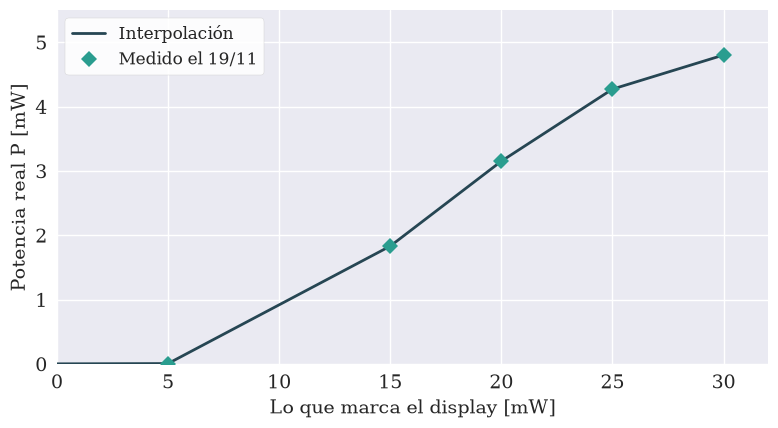

In [2]:
cal = pd.read_csv(os.path.join(DATOS, "cuaderno", "calibracion_potencia.csv"))
esc = po.escalones()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cal.display_mW, cal.potencia_mW, color=AJUSTE, lw=2, zorder=2, label="Interpolación")
m = cal.display_mW > 0
ax.plot(cal.display_mW[m], cal.potencia_mW[m], "D", ms=8, color=SERIE1, zorder=3, label="Medido el 19/11")
ax.set_xlabel("Lo que marca el display [mW]"); ax.set_ylabel(r"Potencia real $P$ [mW]")
ax.set_xlim(0, 32); ax.set_ylim(0, 5.5)
ax.legend(loc="upper left", **LEY)
guardar(fig, "calibracion_potencia")
t = esc[esc.potencia_mW.notna()].copy()
t["barrido"] = t.grabacion.map(NUMERO)
print(t.pivot_table(index="barrido", columns="n", values="potencia_mW").round(2).to_string())

**Qué se ve.** El display no es proporcional a la potencia: por debajo de «5» casi no sale luz (0.004 mW) y después sube. Es lo que hace un láser de diodo, que recién emite por encima de una corriente umbral; es probable que el display muestre algo proporcional a la corriente.

La tabla es la potencia real de cada escalón [mW] que se usa en todo lo que sigue. Dos escalones salen de interpolar y no de un punto medido: el «7» de los barridos 1 y 2 (0.37 mW) y el «20 a 23» del barrido 2 (3.49 mW). El «7» cae en la zona donde la calibración es más empinada y menos segura; el error de ± 0.5 mW lo cubre.

**Errores de la potencia.** Barridos 1 a 6: ± 0.5 mW (indicación de Lenny). Barridos 7 y 8: ± 0.05 mW, que es un supuesto (la última cifra anotada); no cambia nada si es el doble.

## 2. Los datos

Una fila por cuadro con la posición de la partícula atrapada. Las dos grabaciones del 12/11 ya estaban (`resultados/potencia_cuadros.csv`); las seis del 19/11 se miden igual y quedan en `resultados/potencia_cuadros_19-11.csv` (la primera vez relee los videos: unos 15 minutos).

In [3]:
cu_v, ru_v = po.tabla_cuadros()
cu_n, ru_n = po.tabla_cuadros(grabaciones=po.NUEVOS, sufijo="_19-11")
cu = pd.concat([cu_v, cu_n], ignore_index=True)
ru = pd.concat([ru_v, ru_n], ignore_index=True)
for g in po.TODOS:
    d = cu[cu.grabacion == g]
    print("barrido %d  %-20s %d cuadros, %.1f s, período %.1f ms, exposición %s | partícula medida en %d cuadros"
          % (NUMERO[g], g, len(d), d.t_s.max(), 1e3 * d.t_s.diff().median(),
             "%.1f ms" % (1e3 * po.EXPOSICION_S[g]) if g in po.EXPOSICION_S else "no anotada", d.xc_um.notna().sum()))

barrido 1  LASER 5              3165 cuadros, 241.0 s, período 76.0 ms, exposición no anotada | partícula medida en 2760 cuadros
barrido 2  BARRIDO POTENCIAS 2  3006 cuadros, 240.4 s, período 80.0 ms, exposición no anotada | partícula medida en 2575 cuadros
barrido 3  BARRIDO POTENCIAS 3  3332 cuadros, 242.2 s, período 72.0 ms, exposición 30.5 ms | partícula medida en 3302 cuadros
barrido 4  BARRIDO POTENCIAS 4  3369 cuadros, 244.9 s, período 72.0 ms, exposición 30.5 ms | partícula medida en 2444 cuadros
barrido 5  BARRIDO POTENCIAS 5  3319 cuadros, 241.3 s, período 72.0 ms, exposición 30.5 ms | partícula medida en 2295 cuadros
barrido 6  BARRIDO POTENCIAS 6  3311 cuadros, 240.7 s, período 72.0 ms, exposición 30.5 ms | partícula medida en 2374 cuadros
barrido 7  BARRIDO POTENCIAS 7  3305 cuadros, 240.3 s, período 72.0 ms, exposición 30.5 ms | partícula medida en 2608 cuadros
barrido 8  BARRIDO POTENCIAS 8  3322 cuadros, 241.5 s, período 72.0 ms, exposición 30.5 ms | partícula medida en

## 3. ¿Los escalones están donde dice el cuaderno?

Se mira cuánto tiembla la partícula (desvío estándar de $x$ en ventanas de 5 s) a lo largo de cada grabación del 19/11. Si la trampa se afloja en cada cambio de potencia, el temblor tiene que subir en escalones a los tiempos del cuaderno (líneas blancas).

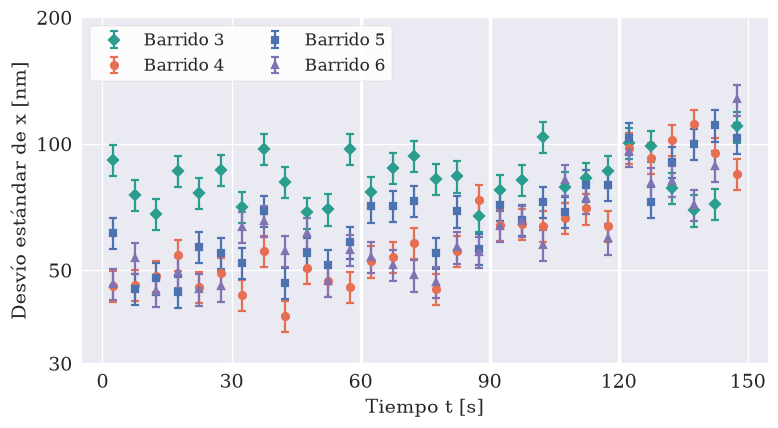

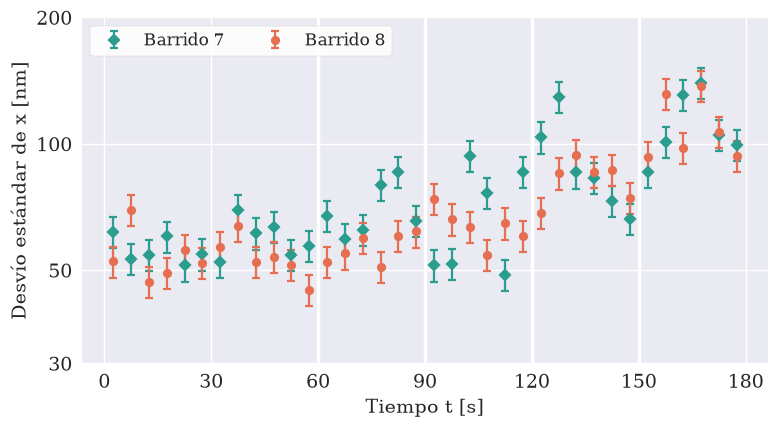

In [4]:
def desvio_en_el_tiempo(grabaciones, nombre, t_max):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for g, c, mk in zip(grabaciones, (SERIE1, SERIE2, AZUL, "#8172B2"), ("D", "o", "s", "^")):
        d = cu[(cu.grabacion == g) & cu.xc_um.notna() & (cu.t_s < t_max)]
        ts, ss, es = [], [], []
        for k, v in d.groupby((d.t_s // 5).astype(int)):
            if len(v) < 40:
                continue
            r = po.quitar_tendencia(v.t_s.values, v.xc_um.values, 1)
            ts.append(v.t_s.mean()); ss.append(1e3 * r.std()); es.append(1e3 * r.std() / np.sqrt(2 * len(r)))
        ax.errorbar(ts, ss, yerr=es, fmt=mk, color=c, mfc=c, mec=c, **{**EB, "ms": 5}, label="Barrido %d" % NUMERO[g])
    for tt in esc[(esc.grabacion == grabaciones[0]) & (esc.t_ini_s > 0) & (esc.t_ini_s < t_max)].t_ini_s:
        ax.axvline(tt, color="white", lw=2.5, zorder=1)
    ax.set_yscale("log"); ax.set_yticks([30, 50, 100, 200]); ax.set_yticklabels(["30", "50", "100", "200"])
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(r"Tiempo $t$ [s]"); ax.set_ylabel(r"Desvío estándar de $x$ [nm]"); ax.set_xticks(range(0, int(t_max) + 1, 30))
    ax.legend(loc="upper left", ncol=2, **LEY)
    guardar(fig, nombre)


desvio_en_el_tiempo(po.NUEVOS[:4], "desvio_tiempo_barridos_3_a_6", 150)
desvio_en_el_tiempo(po.NUEVOS[4:], "desvio_tiempo_barridos_7_y_8", 180)

**Qué se ve.**

- **Barridos 4, 5 y 6:** el temblor sube en cada cambio del cuaderno (a los 60, 90 y 120 s), de unos 45 nm a unos 90 nm. Los escalones están donde dice el cuaderno.
- **Barrido 3:** tiembla el doble desde el principio (80 a 95 nm) y casi no cambia con los escalones. Es la primera señal de que esa grabación es distinta (abajo se ve por qué).
- **Barridos 7 y 8:** suben de unos 55 nm a unos 120 nm, con el salto más claro a los 120 y a los 150 s. El 7 tiene saltos fuera de lugar entre los 75 y los 130 s.

Los cambios caen entre 0 y 2.5 s después de la hora del cuaderno (se ve en el momento en que la partícula se suelta). De cada escalón se descartan los primeros 5 s y el último segundo.

### ¿La partícula está sola y en foco?

La cuenta de la rigidez supone que lo único que mueve a la partícula es la agitación térmica dentro de la trampa. Si otra partícula se le arrima, o si la imagen se desenfoca, la posición medida se ensucia. El seguimiento automático no ve a una vecina que está pegada a la atrapada (las toma como una sola mancha), así que **se miró el video**: un recorte alrededor del láser cada 10 s.

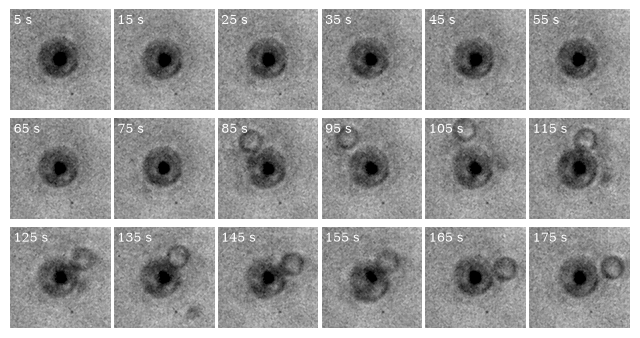

In [5]:
def recortes(g, medio=50, cada=10.0, hasta=180.0):
    # recortes del canal verde alrededor del láser (promedio de 3 cuadros), uno cada `cada` segundos
    if not os.path.isdir(os.path.join(po.GRABACIONES, g)):
        print("no están los videos en", po.GRABACIONES, "-> queda la figura ya guardada"); return
    pag = po.indice_tiff(g)
    tx, ty = CATALOGO[g]["trampa_px"]
    fps = CATALOGO[g]["fps"]
    i0, j0, n = int(round(ty)) - medio, int(round(tx)) - medio, 2 * medio + 1
    ts = np.arange(5.0, hasta, cada)
    fig, axs = plt.subplots(3, 6, figsize=(8, 4.2))
    for ax, t in zip(axs.ravel(), ts):
        k = int(t * fps)
        v = np.mean([po.ventana(pag[k + q], i0, j0, n, n)[..., 1].astype(float) for q in range(3)], axis=0)
        ax.imshow(v / np.median(v), cmap="gray", vmin=0.75, vmax=1.2, interpolation="nearest")
        ax.text(3, 14, "%d s" % t, color="white", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.subplots_adjust(wspace=0.03, hspace=0.03)
    fig.savefig(os.path.join(FIGURAS, "recortes_barrido_%d.svg" % NUMERO[g]), bbox_inches="tight", dpi=150)


for g in ("BARRIDO POTENCIAS 8", "BARRIDO POTENCIAS 3", "BARRIDO POTENCIAS 5", "BARRIDO POTENCIAS 7"):
    recortes(g)
    if g != "BARRIDO POTENCIAS 7":
        plt.close()

La figura que queda a la vista es el barrido 7 (cada recorte mide 9.6 µm de lado; las otras tres están en `figuras/ocho barridos/recortes_barrido_*.svg`). Lo que se ve en cada grabación del 19/11:

| Barrido | Qué se ve | Qué se usa |
|---|---|---|
| 3 | motas claras pegadas a la partícula durante toda la grabación; además sigue retenida entre 150 y 180 s, cuando con «5» en el display tendría que soltarse (en 4, 5 y 6 se suelta a los 150 s) | nada |
| 4 | sola y en foco | todo |
| 5 | bien hasta los 95 s; después la imagen se desenfoca por momentos (100–110 s y 130–142 s) | los dos primeros escalones |
| 6 | sola y en foco | todo |
| 7 | a los 76 s llega otra partícula más chica, a los 84 s la toca y queda pegada hasta los 170 s | el primer escalón |
| 8 | sola y en foco | todo |

En las dos del 12/11 no hay nada cerca de la trampa mientras la partícula está atrapada. Los escalones que no se usan se dibujan igual, con el marcador hueco, y no entran en los ajustes.

In [6]:
NO_SE_USA = {("BARRIDO POTENCIAS 3", n): "motas pegadas a la partícula; no se suelta cuando debería" for n in (1, 2, 3, 4)}
NO_SE_USA.update({("BARRIDO POTENCIAS 5", n): "la imagen se desenfoca por momentos" for n in (3, 4)})
NO_SE_USA.update({("BARRIDO POTENCIAS 7", n): "otra partícula pegada a la atrapada" for n in (2, 3, 4, 5)})
filas = []
for g in po.TODOS:
    for _, e in esc[(esc.grabacion == g) & (esc.n <= po.n_atrapada(g))].iterrows():
        filas.append(dict(grabacion=g, barrido=NUMERO[g], escalon=int(e.n), potencia_mW=e.potencia_mW,
                          limpio=(g, int(e.n)) not in NO_SE_USA, observacion=NO_SE_USA.get((g, int(e.n)), "")))
obs = pd.DataFrame(filas)
csv(obs, "ocho_escalones_que_se_usan.csv")
print("escalones: %d en total, %d limpios" % (len(obs), obs.limpio.sum()))
print(obs.groupby("barrido").limpio.agg(["sum", "count"]).rename(columns={"sum": "limpios", "count": "escalones"}).T.to_string())

escalones: 36 en total, 26 limpios
barrido    1  2  3  4  5  6  7  8
limpios    5  5  0  4  2  4  1  5
escalones  5  5  4  4  4  4  5  5


## 4. El arrastre $\gamma$ de cada partícula

Hace falta para una corrección: la cámara no saca una foto instantánea, promedia la posición durante la exposición, y eso achica el temblor medido. Cuánto lo achica depende de qué tan rápido vuelve la partícula al centro, $\tau_c = \gamma/\kappa$.

$\gamma$ se mide con la misma partícula cuando se apaga el láser: queda suelta y difunde, y $\gamma = k_BT/D$. $D$ sale de cómo crece la varianza de sus desplazamientos con el tiempo (la pendiente, a la que no le entra ni el arrastre del líquido ni el error de medición).

In [7]:
# desde cuándo está suelta: 3 s después del fin del último escalón con trampa
SUELTA_DESDE = {g: float(esc[(esc.grabacion == g) & (esc.n == po.n_atrapada(g))].t_fin_s.iloc[0]) + 3.0 for g in po.TODOS}
SUELTA_DESDE["BARRIDO POTENCIAS 3"] = 183.0      # en el barrido 3 sigue retenida hasta los 180 s (sección 3)
SIN_GAMMA = ("BARRIDO POTENCIAS 3",)                 # con motas pegadas: no se usa
filas = []
for g in po.TODOS:
    d = cu[cu.grabacion == g]
    t_suelta = SUELTA_DESDE[g]
    quien = d[(d.t_s > t_suelta - 10) & (d.t_s < t_suelta - 3) & d.particula.notna()].particula.mode()
    s = d[(d.t_s >= t_suelta) & d.xu_um.notna() & (d.particula == quien.iloc[0])] if len(quien) else d.iloc[:0]
    if g == "LASER 5":
        s = s[s.t_s < 178]                                                       # después se pierde (igual que en el notebook del método)
    if len(s) < 150:
        filas.append(dict(grabacion=g, barrido=NUMERO[g], cuadros=len(s)))
        continue
    r = po.difusion_libre(s.t_s.values, s.xu_um.values, s.yu_um.values)
    D = 0.5 * (r["Dx"] + r["Dy"]); eD = 0.5 * np.hypot(r["err_Dx"], r["err_Dy"])
    filas.append(dict(grabacion=g, barrido=NUMERO[g], t_ini_s=s.t_s.min(), t_fin_s=s.t_s.max(), cuadros=r["n"], Dx_um2_s=r["Dx"],
                      Dy_um2_s=r["Dy"], D_um2_s=D, err_D=eD, gamma_1e8_N_s_m=kT / D * 1e2, err_gamma_1e8=kT / D * 1e2 * eD / D))
gam = pd.DataFrame(filas)
csv(gam, "ocho_gamma.csv")
print(gam.round(3).to_string(index=False))
GAMMA = {}
for dia, grabs in (("12/11", po.BARRIDOS), ("19/11", po.NUEVOS)):
    v = gam[gam.grabacion.isin(grabs) & gam.D_um2_s.notna() & ~gam.grabacion.isin(SIN_GAMMA)]
    w = 1 / v.err_gamma_1e8 ** 2
    media, err = float((w * v.gamma_1e8_N_s_m).sum() / w.sum()), float(max(1 / np.sqrt(w.sum()), v.gamma_1e8_N_s_m.std() / np.sqrt(len(v)) if len(v) > 1 else 0))
    print("%s: gamma = (%.1f ± %.1f)·1e-8 N·s/m (%d grabaciones)" % (dia, media, err, len(v)))
    for g in grabs:
        GAMMA[g] = media * 1e-8

          grabacion  barrido  t_ini_s  t_fin_s  cuadros  Dx_um2_s  Dy_um2_s  D_um2_s  err_D  gamma_1e8_N_s_m  err_gamma_1e8
            LASER 5        1   153.03   173.60      230     0.095     0.054    0.075  0.013            5.485          0.924
BARRIDO POTENCIAS 2        2   153.03   211.66      662     0.077     0.057    0.067  0.007            6.081          0.677
BARRIDO POTENCIAS 3        3   183.03   242.22      785     0.081     0.055    0.068  0.005            6.039          0.439
BARRIDO POTENCIAS 4        4   153.00   178.59      340     0.082     0.068    0.075  0.006            5.440          0.445
BARRIDO POTENCIAS 5        5      NaN      NaN        3       NaN       NaN      NaN    NaN              NaN            NaN
BARRIDO POTENCIAS 6        6   153.00   174.23      270     0.081     0.076    0.079  0.008            5.206          0.563
BARRIDO POTENCIAS 7        7      NaN      NaN       91       NaN       NaN      NaN    NaN              NaN            NaN
BARRIDO 

**Qué se ve.** El arrastre de la partícula es el mismo los dos días: $(5.9 \pm 0.5)\times10^{-8}$ N·s/m el 12/11 y $(5.5 \pm 0.4)\times10^{-8}$ el 19/11. O sea que las partículas son del mismo tamaño y el líquido tiene la misma viscosidad. En los barridos 5 y 7 no se pudo medir (la partícula se pierde enseguida al soltarse) y el 3 no se usa (sección 3); para todos se toma el promedio del día. Alcanza, porque $\gamma$ solo entra en la corrección por la exposición.

## 5. La rigidez de cada escalón

Para cada grabación, escalón y eje: varianza de la posición (sin la deriva lenta), menos el error de medición (el de píxel, medido en cada grabación), y la corrección por la exposición.

- **19/11 (barridos 3 a 8):** la exposición se anotó, 30.5 ms. La corrección es exacta.
- **12/11 (barridos 1 y 2):** la exposición no se anotó. Se supone medio período (unos 39 ms), como en el notebook del método; al lado van los valores que saldrían con exposición cero y con el período entero.

In [8]:
tab_v, det_v = po.analizar_escalones(cu, ru, GAMMA, T, W_rel=(0.0, 0.5, 1.0), n_boot=300, grabaciones=po.BARRIDOS)
tablas, det = [tab_v], dict(det_v)
for g in po.NUEVOS:
    dt = cu[cu.grabacion == g].t_s.diff().median()
    t_, d_ = po.analizar_escalones(cu, ru, GAMMA, T, W_rel=(po.EXPOSICION_S[g] / dt,), n_boot=300, grabaciones=(g,))
    tablas.append(t_); det.update(d_)
tab = pd.concat(tablas, ignore_index=True)
tab["err_kappa_total"] = np.hypot(tab.err_kappa_equiparticion, tab.err_kappa_ruido)
central = tab[(tab.W_rel == 0.5) | tab.grabacion.isin(po.NUEVOS)].copy()
for wr, nom in ((0.0, "kappa_si_exposicion_cero"), (1.0, "kappa_si_exposicion_un_periodo")):
    o = tab[tab.W_rel == wr].set_index(["grabacion", "escalon", "eje"]).kappa_equiparticion
    central[nom] = o.reindex(pd.MultiIndex.from_frame(central[["grabacion", "escalon", "eje"]])).values
central["barrido"] = central.grabacion.map(NUMERO)
central = central.merge(obs[["grabacion", "escalon", "limpio"]], on=["grabacion", "escalon"])
central["desvio_medido_nm"] = 1e3 * np.sqrt(central.var_um2)
central["ruido_nm"] = 1e3 * np.sqrt(central.ruido_um2)
ESC = central[["barrido", "grabacion", "escalon", "potencia_mW", "err_potencia_mW", "display_mW", "eje", "n", "W_s", "desvio_medido_nm",
               "ruido_nm", "kappa_equiparticion", "err_kappa_equiparticion", "err_kappa_ruido", "err_kappa_total",
               "kappa_si_exposicion_cero", "kappa_si_exposicion_un_periodo", "limpio", "media_um", "t_ini_usado_s", "t_fin_usado_s"]]
ESC = ESC.rename(columns={"kappa_equiparticion": "kappa_pN_um", "err_kappa_equiparticion": "err_kappa_estadistico", "n": "cuadros"})
v = ESC.pivot_table(index=["barrido", "potencia_mW"], columns="eje", values=["desvio_medido_nm", "ruido_nm", "kappa_pN_um", "err_kappa_total"])
print(v.round(2).sort_index(level=[0, 1], ascending=[True, False]).to_string())

                    desvio_medido_nm         err_kappa_total       kappa_pN_um       ruido_nm       
eje                                x       y               x     y           x     y        x      y
barrido potencia_mW                                                                                 
1       4.8000                 43.01   45.53            0.20  0.12        2.03  1.72    22.08  19.29
        4.2700                 50.83   55.39            0.17  0.14        1.46  1.19    22.08  19.29
        3.1500                 56.88   64.96            0.11  0.08        1.17  0.89    22.08  19.29
        1.8300                 79.91   87.81            0.07  0.07        0.61  0.50    22.08  19.29
        0.3695                173.09  129.58            0.02  0.02        0.13  0.24    22.08  19.29
2       4.8000                 53.01   53.63            0.68  0.25        2.11  1.59    39.30  31.95
        4.2700                 57.10   50.91            0.37  0.31        1.68  1.80    39.

**Cómo leer la tabla.** `desvio_medido` es cuánto tiembla la partícula, `ruido` es el error de medición de la posición (se resta), y `kappa` es la rigidez con su error (el estadístico más el de no conocer el ruido mejor que ± 10 %).

- El error de medición es de unos 20 nm en casi todas; en el barrido 7 es de 30 a 44 nm (la partícula está fuera de foco) y en el barrido 2, de 32 a 39 nm.
- En los barridos limpios la rigidez baja escalón a escalón. A potencia máxima (4.8 mW), en $x$, va de 1.0 a 1.5 pN/µm el 19/11 y es de 2.0 a 2.1 pN/µm el 12/11.
- El barrido 3 da 0.4 a 0.7 pN/µm sin relación con la potencia, y el 7 se desordena después del primer escalón: son los que tienen algo pegado a la partícula.

## 6. ¿Se repite? La misma partícula en tres barridos

Los barridos 4, 5 y 6 son la misma partícula (confirmado en el cuaderno), con los mismos escalones. Es la mejor prueba de cuánto se repite la medición: tendrían que dar lo mismo dentro del error.

In [9]:
s = ESC[ESC.barrido.isin([4, 5, 6]) & ESC.limpio]
rep = s.pivot_table(index=["eje", "display_mW"], columns="barrido", values="kappa_pN_um")
err = s.pivot_table(index=["eje", "display_mW"], columns="barrido", values="err_kappa_total")
rep["media"] = rep[[4, 5, 6]].mean(axis=1)
rep["dispersion_%"] = 100 * rep[[4, 5, 6]].std(axis=1) / rep.media          # cuánto difieren entre sí
rep["error_calculado_%"] = 100 * (err[[4, 5, 6]].mean(axis=1) / rep.media)  # cuánto dice el error de cada una
print(rep.sort_index(level=[0, 1], ascending=[True, False]).round(2).to_string())
DISP = float(np.sqrt((rep["dispersion_%"] ** 2).mean())) / 100
CALC = float(np.sqrt((rep["error_calculado_%"] ** 2).mean())) / 100
EXTRA = float(np.sqrt(max(DISP ** 2 - CALC ** 2, 0.0)))
print("\nen promedio: difieren %.0f %% entre sí; el error calculado de cada una es %.0f %% -> falta un %.0f %% que el error de una sola grabación no ve"
      % (100 * DISP, 100 * CALC, 100 * EXTRA))
ESC["err_kappa_final"] = np.hypot(ESC.err_kappa_total, EXTRA * ESC.kappa_pN_um)
csv(ESC, "ocho_escalones.csv")

barrido            4     5     6  media  dispersion_%  error_calculado_%
eje display_mW                                                          
x   30.0        1.50  1.03  1.19   1.24         19.43               8.41
    25.0        1.09  0.70  1.36   1.05         31.40              10.67
    20.0        0.76   NaN  0.69   0.72          7.22              10.43
    15.0        0.32   NaN  0.43   0.38         20.72              16.53
y   30.0        1.36  1.36  1.56   1.43          7.99               8.31
    25.0        1.05  1.06  1.08   1.06          1.51               9.97
    20.0        0.75   NaN  0.55   0.65         21.85              17.84
    15.0        0.44   NaN  0.51   0.47         11.49              10.24

en promedio: difieren 18 % entre sí; el error calculado de cada una es 12 % -> falta un 13 % que el error de una sola grabación no ve


**Qué se ve.** La misma partícula, medida tres veces a la misma potencia, da rigideces que difieren 18 % entre sí. El error que se calcula dentro de cada grabación es 12 %. La diferencia (13 %) es algo que cambia de una grabación a la otra y que una grabación sola no ve: la altura de la partícula, el foco, una deriva lenta.

**Decisión:** a todos los puntos se les suma ese 13 % al error (en cuadratura: raíz de la suma de los cuadrados). Es el error que se usa en la figura y en los ajustes de la sección siguiente (`err_kappa_final` en `ocho_escalones.csv`).

## 7. Rigidez contra potencia real

Si la trampa es más fuerte cuanta más luz hay, la rigidez tiene que ser proporcional a la potencia: $\kappa = b\,P$, una recta por el origen. Se ajusta esa recta a cada grupo de barridos y se dibujan todos juntos.

Los ajustes tienen en cuenta el error de la potencia además del de la rigidez (un punto con ± 0.5 mW pesa mucho menos que uno con ± 0.05 mW). Los marcadores huecos son los escalones que no se usan (sección 3).

                           grupo eje  puntos  pendiente_pN_um_mW  err_pendiente   chi2  gl  recta_libre_ordenada_pN_um  err_ordenada  recta_libre_pendiente  err_recta_libre_pendiente  recta_libre_chi2  recta_libre_gl
 Barridos 1 y 2 (12/11, display)   x      10               0.398          0.036  7.559   9                       0.197         0.132                  0.334                      0.054             7.064               8
 Barridos 3 a 6 (19/11, display)   x      10               0.235          0.017  8.591   9                      -0.131         0.188                  0.271                      0.053             7.220               8
Barridos 7 y 8 (potencia medida)   x       6               0.222          0.015  4.613   5                      -0.105         0.090                  0.259                      0.036             3.206               4
  Todo el 19/11 (barridos 4 a 8)   x      16               0.228          0.011 13.731  15                      -0.114         0.077

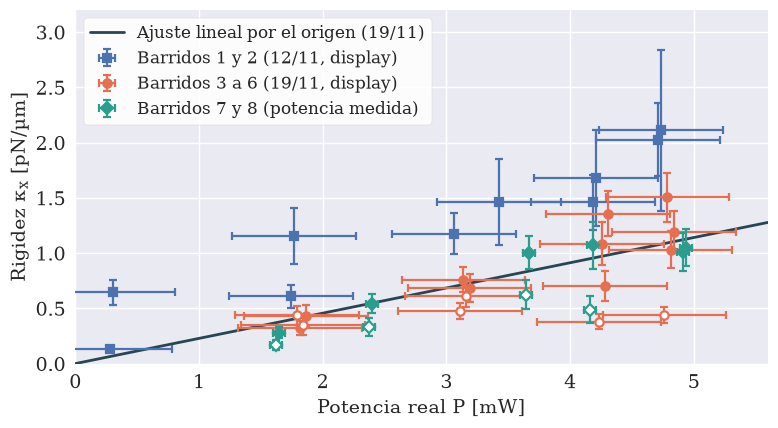

In [10]:
def recta_por_el_origen(x, y, ex, ey, vueltas=20):
    # y = b·x con error en los dos ejes: el error de x se pasa a y con la pendiente (b·ex) y se repite hasta que b no cambia.
    # Devuelve b, su error, chi2 y grados de libertad.
    x, y, ex, ey = (np.asarray(v, float) for v in (x, y, ex, ey))
    b = np.sum(x * y) / np.sum(x * x)
    for _ in range(vueltas):
        w = 1 / (ey ** 2 + (b * ex) ** 2)
        b = np.sum(w * x * y) / np.sum(w * x * x)
    return b, 1 / np.sqrt(np.sum(w * x * x)), float(np.sum(w * (y - b * x) ** 2)), len(x) - 1


def recta_libre(x, y, ex, ey, vueltas=20):
    # y = a + b·x con error en los dos ejes (igual que arriba). Devuelve el dict de po.ajuste_lineal.
    b = np.polyfit(x, y, 1)[0]
    for _ in range(vueltas):
        f = po.ajuste_lineal(x, y, np.hypot(ey, b * np.asarray(ex, float)))
        b = f["b"]
    return f


def ajustar(q, nombre, eje):
    b, eb, chi2, gl = recta_por_el_origen(q.potencia_mW, q.kappa_pN_um, q.err_potencia_mW, q.err_kappa_final)
    f = recta_libre(q.potencia_mW, q.kappa_pN_um, q.err_potencia_mW, q.err_kappa_final)
    return dict(grupo=nombre, eje=eje, puntos=len(q), pendiente_pN_um_mW=b, err_pendiente=eb, chi2=chi2, gl=gl,
                recta_libre_ordenada_pN_um=f["a"], err_ordenada=f["err_a"], recta_libre_pendiente=f["b"],
                err_recta_libre_pendiente=f["err_b"], recta_libre_chi2=f["chi2"], recta_libre_gl=f["gl"])


filas = []
for eje in "xy":
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for clave, (grabs, color, mk, nombre) in GRUPOS.items():
        s = ESC[ESC.grabacion.isin(grabs) & (ESC.eje == eje)]
        for sel, hueco in ((s.limpio, False), (~s.limpio, True)):
            q = s[sel]
            if len(q):
                corrido = q.potencia_mW + 0.025 * (q.barrido - 4.5)      # un poco corridos para que no se tapen
                ax.errorbar(corrido, q.kappa_pN_um, xerr=q.err_potencia_mW, yerr=q.err_kappa_final, fmt=mk, color=color,
                            mfc="white" if hueco else color, mec=color, **{**EB, "ms": 6}, label=None if hueco else nombre)
        filas.append(ajustar(s[s.limpio], nombre, eje))
    dia19 = ESC[ESC.grabacion.isin(po.NUEVOS) & (ESC.eje == eje) & ESC.limpio]
    filas.append(ajustar(dia19, "Todo el 19/11 (barridos 4 a 8)", eje))
    pp = np.array([0, 5.6])
    ax.plot(pp, filas[-1]["pendiente_pN_um_mW"] * pp, color=AJUSTE, lw=2, zorder=2, label="Ajuste lineal por el origen (19/11)")
    ax.set_xlim(0, 5.6); ax.set_ylim(0, 3.2)
    ax.set_xlabel(r"Potencia real $P$ [mW]"); ax.set_ylabel(r"Rigidez $\kappa_%s$ [pN/µm]" % eje)
    ax.legend(loc="upper left", **LEY)
    guardar(fig, "rigidez_potencia_%s" % eje)
    if eje == "y":
        plt.close(fig)
aj = pd.DataFrame(filas)
csv(aj, "ocho_ajustes.csv")
print(aj.round(3).to_string(index=False))

**Cómo leer la tabla.** `pendiente` es $b$ de la recta por el origen, en pN/µm por cada mW. `chi2` mide cuánto se apartan los puntos de la recta en unidades de su error: si vale parecido a `gl` (cantidad de puntos menos parámetros), la recta describe bien los datos. La «recta libre» es la misma recta pero dejando que no pase por el origen; si su ordenada es compatible con cero, la proporcionalidad está bien.

**Qué se ve.**

- **El 19/11 la rigidez es proporcional a la potencia.** Con los 16 escalones limpios: $\kappa_x = (0.228 \pm 0.011)\,P$ y $\kappa_y = (0.276 \pm 0.013)\,P$, en pN/µm con $P$ en mW. El $\chi^2$ es 13.7 y 10.6 con 15 grados de libertad, y la ordenada de la recta libre es compatible con cero ($-0.11 \pm 0.08$ y $-0.07 \pm 0.10$ pN/µm).
- **La calibración del display funciona.** Los barridos 4 a 6 (display convertido a potencia real) dan $0.235 \pm 0.017$ en $x$; los barridos 7 y 8 (potencia medida directamente) dan $0.222 \pm 0.015$. Coinciden. En $y$: $0.258 \pm 0.018$ y $0.295 \pm 0.019$, a 1.4 desvíos.
- **El 12/11 la trampa era más rígida a igual potencia:** $0.398 \pm 0.036$ en $x$ y $0.345 \pm 0.029$ en $y$, entre 1.3 y 1.7 veces más que el 19/11. No es un problema del método: el 12/11 la rigidez medida arrastrando la partícula con la platina (objetivo 2, que no depende de la exposición ni del error de medición) dio 1.9 ± 0.2 pN/µm a potencia máxima, lo mismo que acá (2.0 a 2.1). Hay dos explicaciones y con estos datos no se puede elegir: o la trampa estaba mejor el 12/11 (otra alineación, otro foco, otra altura de la partícula), o la calibración del 19/11 no vale para el 12/11 (a igual número en el display, llegaba más potencia a la muestra).
- **El «7» del display** (barridos 1 y 2, el punto de más a la izquierda): el barrido 1 cae sobre su recta; el barrido 2 queda por encima (0.64 pN/µm donde la recta daría 0.15). Ese punto sale de interpolar la calibración en su zona menos segura, y con ± 0.5 mW no alcanza para decir nada.
- En el 19/11 la trampa es algo más rígida en $y$ que en $x$ ($\kappa_y/\kappa_x \approx 1.2$); el 12/11 era al revés (0.87).

## 8. La forma del pozo en un barrido nuevo

El mismo dibujo que en el notebook del método: del histograma de posiciones de cada escalón sale el potencial, $U(x) = -k_BT\ln N(x)$. Cada escalón da una parábola; cuanto menos potencia, más abierta.

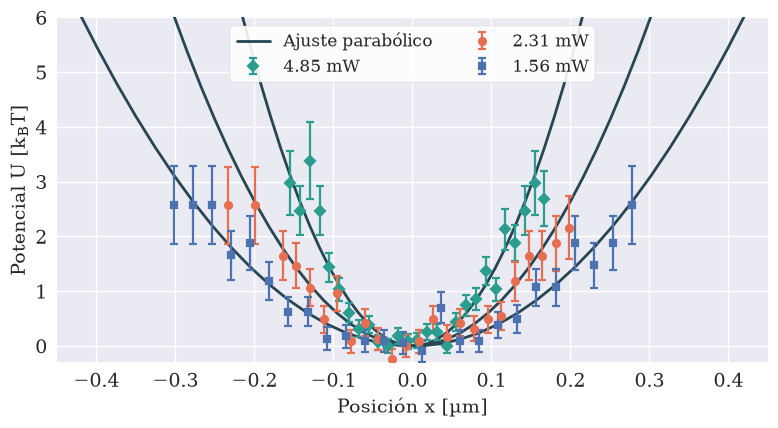

In [11]:
g_p, eje_p = "BARRIDO POTENCIAS 8", "x"
fig, ax = plt.subplots(figsize=(8, 4.5))
kTJ = po.KB * T
filas = []
for n, c_, mk in ((1, SERIE1, "D"), (4, SERIE2, "o"), (5, AZUL, "s")):
    clave = [k for k in det if k[0] == g_p and k[1] == n and k[2] == eje_p][0]
    gr = det[clave]["graficos"]
    x = gr["x_hist"] * 1e6
    U0 = np.nanmin(gr["U_ajuste"])
    ok = np.isfinite(gr["U"]) & (gr["err_U"] / kTJ < 0.75)
    P = esc[(esc.grabacion == g_p) & (esc.n == n)].potencia_mW.iloc[0]
    ax.errorbar(x[ok], (gr["U"][ok] - U0) / kTJ, yerr=gr["err_U"][ok] / kTJ, fmt=mk, color=c_, mfc=c_, mec=c_,
                **{**EB, "ms": 5}, label="%.2f mW" % P)
    ax.plot(x, (gr["U_ajuste"] - U0) / kTJ, color=AJUSTE, lw=2, zorder=2, label="Ajuste parabólico" if n == 5 else None)
    for xi, Ui, ei, Ua in zip(x, gr["U"], gr["err_U"], gr["U_ajuste"]):
        filas.append(dict(grabacion=g_p, escalon=n, potencia_mW=P, eje=eje_p, x_um=xi, U_kT=(Ui - U0) / kTJ, err_U_kT=ei / kTJ,
                          U_parabola_kT=(Ua - U0) / kTJ))
ax.set_xlabel(r"Posición $%s$ [µm]" % eje_p); ax.set_ylabel(r"Potencial $U$ [$k_BT$]")
ax.set_ylim(-0.3, 6); ax.set_xlim(-0.45, 0.45)
ax.legend(loc="upper center", ncol=2, **LEY)
guardar(fig, "potencial_%s_%s" % (g_p.replace(" ", "_"), eje_p))
csv(pd.DataFrame(filas), "ocho_potencial_%s_%s.csv" % (g_p.replace(" ", "_"), eje_p))

**Qué se ve en el pozo.** En el barrido 8 las tres parábolas se abren al bajar la potencia y los puntos caen sobre ellas hasta donde llega la partícula (2 a 3 $k_BT$): cerca del centro el pozo es parabólico, igual que el 12/11.

## 9. Conclusiones

**Lo que se puede afirmar**

1. Con la potencia real, **la rigidez de la trampa es proporcional a la potencia**: el 19/11, $\kappa_x = (0.228 \pm 0.011)$ y $\kappa_y = (0.276 \pm 0.013)$ pN/µm por mW, entre 1.56 y 4.85 mW.
2. **La calibración del display sirve:** los barridos con display calibrado y los de potencia medida dan la misma pendiente.
3. **La medición se repite dentro de un 18 %** (misma partícula, tres barridos). El error de cada punto ya incluye eso.
4. A potencia máxima (4.8 mW reales) la rigidez en $x$ es de 1.0 a 1.5 pN/µm el 19/11 y de 2.0 a 2.1 pN/µm el 12/11.
5. El arrastre $\gamma$ de las partículas es el mismo los dos días (5.5 y 5.9 ×10⁻⁸ N·s/m).

**Lo que queda abierto**

- **Por qué el 12/11 la trampa era 1.3 a 1.7 veces más rígida** a igual potencia calibrada. ¿Se tocó la alineación o el foco entre los dos días? ¿La calibración del 19/11 vale para el 12/11?
- **La exposición del 12/11** sigue sin conocerse (se supuso medio período). Para el 19/11 ya no es una duda: 30.5 ms.
- **El barrido 3** no se usa: motas pegadas a la partícula y no se suelta a los 150 s. Si en esa grabación el último escalón no fue «5», conviene anotarlo.
- **El barrido 7**, que es uno de los dos de potencia medida, solo aporta su primer escalón: a los 76 s se le pega otra partícula. De los de potencia medida, el que vale entero es el 8.
- **El error de la potencia de los barridos 7 y 8** (± 0.05 mW) es un supuesto.
- **El escalón más bajo de los barridos 3 a 6** («5» en el display, 0.004 mW) no retiene a la partícula: no da un punto de rigidez, pero confirma que ahí casi no hay luz.

Las tablas quedan en `resultados/ocho_*.csv` (`LEEME.txt` explica las columnas).